In [1]:
%pylab inline
import os
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTable
import catutil as utilities
import healpy as hp

Populating the interactive namespace from numpy and matplotlib


# S19A PSF (new star mask) not in new FD cut
The new FDFC cut with f-delta$<0.01$ cut

In [2]:
def get_FDFC_flag(data,version,degree=True):
    ra,dec  =   utilities.get_radec(data)
    # Read fdfc file
    if version=='s16':
        hpfname =   "s16a_wide2_fdfc.fits"
    elif version=='s18':
        hpfname =   "s18a_fdfc_hp_contarea.fits"
    elif version=='s19':
        hpfname =   "s19a_fdfc_hp_contarea_izy-gt-5_trimmed_fd001.fits"
    else:
        return np.ones(len(ra),dtype=bool)
    hpfname =   os.path.join('/work/xiangchong.li/work/galSim-HSC/database',hpfname)
    m       =   hp.read_map(hpfname, nest = True, dtype = np.bool)

    # Get flag
    if degree:
        mfactor =   np.pi/180.
    else:
        mfactor =   1.
    indices_map =   np.where(m)[0]
    nside   =   hp.get_nside(m)
    phi     =   ra*mfactor
    theta   =   np.pi/2. - dec*mfactor
    indices_obj = hp.ang2pix(nside, theta, phi, nest = True)
    return np.in1d(indices_obj, indices_map)

In [3]:
hpfname0=   's19a_fdfc_hp_contarea_izy-gt-5_trimmed.fits'
hpfname0=   os.path.join('/work/xiangchong.li/work/galSim-HSC/database',hpfname0)
m0      =   hp.read_map(hpfname0, nest = True, dtype = np.bool)
hpfname =   's19a_fdfc_hp_fd_float.fits'
hpfname =   os.path.join('/work/xiangchong.li/work/galSim-HSC/database',hpfname)
m_fd    =   hp.read_map(hpfname, nest = True, dtype = np.float)
sel     =   m_fd<0.01

NSIDE = 1024
ORDERING = RING in fits file
INDXSCHM = IMPLICIT
Ordering converted to NEST
NSIDE = 1024
ORDERING = RING in fits file
INDXSCHM = IMPLICIT
Ordering converted to NEST


In [9]:
np.sum(sel)/np.sum(m0)

77.93746747292508

In [ ]:
m0[~sel]=   False
hpfname1=   's19a_fdfc_hp_contarea_izy-gt-5_trimmed_fd001.fits'
hpfname1=   os.path.join('/work/xiangchong.li/work/galSim-HSC/database',hpfname1)
hp.write_map(hpfname1,m0,nest=True,overwrite=True)

/work/xiangchong.li/hscpipe7/python/miniconda3-4.5.12/envs/lsst-scipipe-1172c30/lib/python3.7/site-packages/matplotlib/pyplot.py:1479: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ret = ax.set_ylim(*args, **kwargs)


Text(0.5, 1.0, 'Histogram')

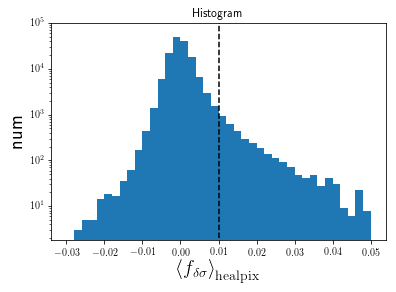

In [71]:
plt.hist(m[m!=0.],range=(-0.03,0.05),bins=40)
plt.yscale('log')
plt.vlines(0.01,0,1e5,linestyles='--')
plt.ylim(0,1e5)
plt.xlabel(r'$\left\langle f_{\delta\sigma} \right \rangle_{\rm{healpix}}$',fontsize=20)
plt.ylabel('num',fontsize=20)
plt.title('Histogram')

In [42]:
fieldname='XMM'
psfs1=pyfits.getdata('wrkDir/database/s19-Hironao-2/fields/%s_psfstars.fits' %fieldname)
psfs1=psfs1[~psfs1['i_pixelflags_inexact_psfcenter']]

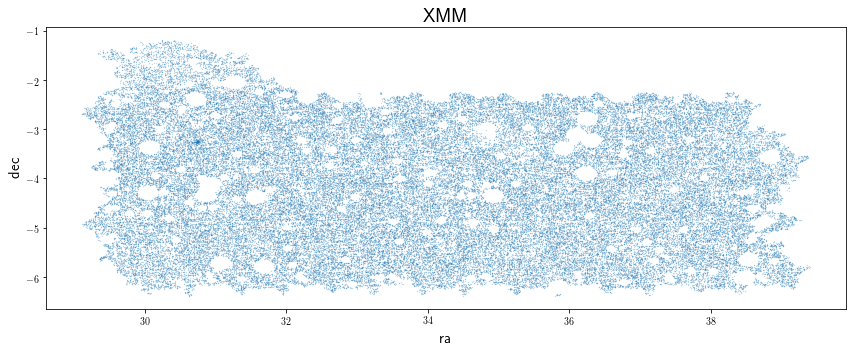

In [43]:
raP=psfs1['i_ra']
decP=psfs1['i_dec']
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fieldname,fontsize=20)
plt.scatter(raP,decP,s=0.05,alpha=0.5)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

In [228]:
hpfname0="s19a_fdfc_hp_contarea_izy-gt-5_trimmed.fits"
maskP0=get_FDFC_flag(raP,decP,hpfname=hpfname0)
print(np.sum(maskP0))
print(len(maskP0))
print(1.-np.sum(maskP0)/len(maskP0))

NSIDE = 1024
ORDERING = RING in fits file
INDXSCHM = IMPLICIT
Ordering converted to NEST
24240
24240
0.0


In [ ]:
hpfname1="s19a_fdfc_hp_contarea_izy-gt-5_trimmed_fd001.fits"
maskP1=get_FDFC_flag(raP,decP,hpfname=hpfname1)
print(np.sum(maskP1))
print(len(maskP1))
print(1.-np.sum(maskP1)/len(maskP1))

NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
0.014439963574866654
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
0.03151815181518147
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
0.04982206405693945
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
0.014544492926087504
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
0.025518695218018417
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
0.014303877940241572


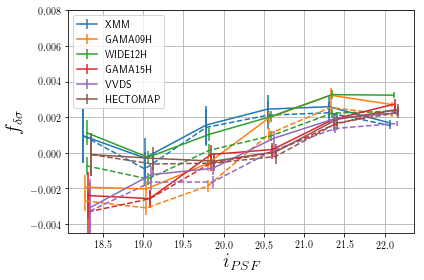

In [83]:
hpfname1="s19a_fdfc_hp_contarea_izy-gt-5_trimmed_fd001.fits"
colors=plt.get_cmap('tab10')
bins=np.array([17.929384, 18.691153, 19.45292 , 20.214687, 20.976456, 21.738224,22.499992], dtype=float32)
#bins=np.array([5., 100, 250, 400, 1000,8000], dtype=float32)
bave=(bins[:-1]+bins[1:])/2.
plt.figure()
nAll2=0.
nMasked2=0.
i=0
for fn in utilities.field_names.keys():
    cat=pyfits.getdata('wrkDir/database/s19-Hironao-3/fields/%s_nonpsfstars.fits' %fn)
    rpsf=utilities.get_psf_size(cat,type='det')
    rstar=utilities.get_gal_size(cat,type='det')
    fdelta=(rpsf-rstar)/rstar
    maskG=np.ones(len(fdelta),dtype=np.bool)
    maskG=maskG&get_FDFC_flag(cat,'s19')
    print(1-np.sum(maskG)/len(maskG))
    nAll2+=len(maskG)
    nMasked2+=np.sum(~maskG)
    mag=cat['i_psfflux_mag']
    snr=cat['i_psfflux_flux']/cat['i_psfflux_fluxerr']
    obs=mag
    a=np.histogram(obs,bins=bins)[0]
    b=np.histogram(obs,bins=bins,weights=fdelta)[0]
    c=np.sqrt(np.histogram(obs,bins=bins,weights=fdelta**2.)[0])
    plt.errorbar(bave+(i-2.5)*0.02,b/a,c/a,label=fn,c=colors(i))
    fdelta=fdelta[maskG]
    obs=obs[maskG]
    a=np.histogram(obs,bins=bins)[0]
    b=np.histogram(obs,bins=bins,weights=fdelta)[0]
    c=np.sqrt(np.histogram(obs,bins=bins,weights=fdelta**2.)[0])
    plt.errorbar(bave+(i-2.5)*0.02,b/a,c/a,c=colors(i),ls='--')
    i+=1
plt.xlabel(r'$i_{PSF}$',fontsize=20)
plt.ylabel(r'$f_{\delta\sigma}$',fontsize=20)
plt.ylim(-0.0045,0.008)
plt.legend(fontsize=10)
plt.tight_layout()
#plt.xscale('log')
plt.grid()

In [80]:
print(nAll2,nMasked2)
print(nMasked2/nAll2)

87131.0 2697.0
0.03095339201891405


In [58]:
print(nAll2,nMasked2)
print(nMasked2/nAll2)

2256213.0 0.0
0.0


In [147]:
fieldname='GAMA09H'
cat=pyfits.getdata('wrkDir/database/s19-Hironao-2/fields/%s_psfstars.fits' %fieldname)
rpsf=utilities.get_psf_size(cat,type='det')
rstar=utilities.get_gal_size(cat,type='det')
fdelta=(rpsf-rstar)/rstar
seeing=utilities.get_psf_size(cat,type='fwhm')
mag=cat['i_psfflux_mag']
ra=cat['i_ra']
dec=cat['i_dec']
num_map,ra_map,fdelta_map=healpix_2d_scatter(ra,dec,ra,fdelta)
num_map,dec_map,fdelta_map=healpix_2d_scatter(ra,dec,dec,fdelta)
mask=num_map>0.1

Text(0, 0.5, '$f_{\\delta\\sigma}$')

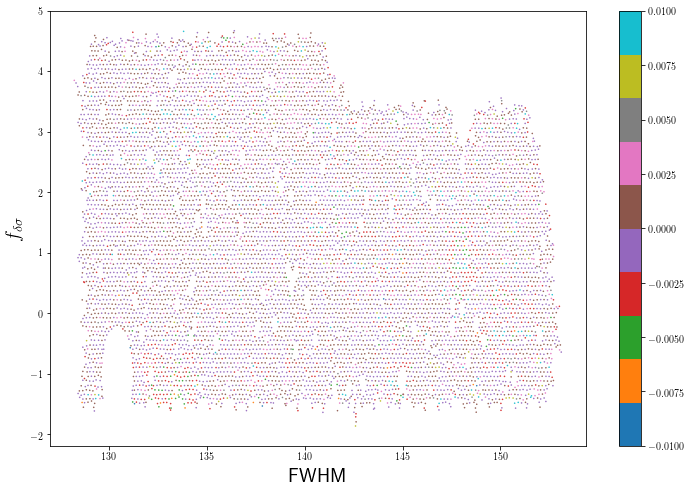

In [167]:
plt.figure(figsize=(12,8))
plt.scatter(ra_map[mask],dec_map[mask],s=0.3,c=fdelta_map[mask],vmin=-0.01,vmax=0.01,cmap='tab10')
plt.colorbar()
#plt.hist(num_map[mask],weights=fdelta_map[mask])
#plt.xlim(0.4,1.0)
plt.xlabel('FWHM',fontsize=20)
plt.ylabel(r'$f_{\delta\sigma}$',fontsize=20)

In [142]:
def healpix_2d_scatter(ra,dec,o1,o2,hpfname="s19a_fdfc_hp_contarea_izy-gt-5_trimmed_fd001.fits"):
    # Read fdfc file
    hpfname =   os.path.join('/work/xiangchong.li/work/galSim-HSC/database',hpfname)
    m       =   hp.read_map(hpfname, nest = True, dtype = np.bool)
    indices_map = np.where(m)[0]
    nside = hp.get_nside(m)
    phi = np.radians(ra)
    theta = np.radians(90.-dec)
    hp_indices = hp.ang2pix(nside, theta, phi, nest = True)

    set_indices = list(set(hp_indices))
    set_indices = list(set([int(i//4) for i in set_indices]))
    hp_indices_quarter = np.int_(hp_indices/4)
    
    num_map = np.zeros(int(len(m)/4))
    o1_map = np.zeros(int(len(m)/4))
    o2_map = np.zeros(int(len(m)/4))

    for i in set_indices:
        sel = np.equal(hp_indices_quarter, i)
        num_map[i] = np.sum(sel)
        o1_map[i] = np.average(o1[sel])
        o2_map[i] = np.average(o2[sel])
    return num_map,o1_map,o2_map

In [7]:
hpfname ="s19a_fdfc_hp_contarea_izy-gt-5_trimmed_fd001.fits"
hpfname =   os.path.join('/work/xiangchong.li/work/galSim-HSC/database',hpfname)
a=hp.read_map(hpfname, nest = True, dtype = np.bool)

NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT


In [8]:
hpfname ="s19a_fdfc_hp_contarea_izy-gt-5_trimmed.fits"
hpfname =   os.path.join('/work/xiangchong.li/work/galSim-HSC/database',hpfname)
b=hp.read_map(hpfname, nest = True, dtype = np.bool)

NSIDE = 1024
ORDERING = RING in fits file
INDXSCHM = IMPLICIT
Ordering converted to NEST


In [21]:
print(1-np.sum(a)/np.sum(b))
print(np.sum(a)/np.sum(b)*444.61)

0.02164134717850863
434.98804063096327


In [22]:
(1-0.022)*444.61

434.82858